# 05 — QTAF-Net: Question-Type-Aware Multimodal Fusion for PathVQA

**Proposed research architecture, fully trained from scratch.** Combines a spatial CNN, BiLSTM, question-guided attention, a learned question-type classifier, and type-conditioned visual/language fusion. This is a **research implementation**, not a published architecture reproduction.

**Fair comparison:** same cleaned PathVQA splits, 1,000-class open-answer mapping, image preprocessing, question tokenization, and oracle-routing metric as prior baselines. Also report **predicted-type routing** to evaluate a deployable inference setting. Baselines were not evaluated with predicted routing, so do not directly claim a fair predicted-routing comparison without re-evaluating them.

**No external pretrained weights.** The earlier `late_fusion_latest.pth` is used **only to read vocabularies**. The QTAF-Net model starts randomly initialized. No test data are used for model selection.

**Run in order.** Fine-tuning loads the best original checkpoint and uses a fresh optimizer. Checkpoints, histories, figures, and backups are uniquely named.

### Submission and execution guide (documentation only)

**Purpose.** This notebook implements the proposed QTAF-Net architecture for pathology visual question answering. It contains original training, fine-tuning, validation, attention visualization, and checkpoint export. It does **not** perform the final held-out test evaluation.

**Kaggle setup.** Use a GPU-enabled Kaggle notebook with Internet access when downloading `flaviagiammarino/path-vqa`. Attach a Kaggle input dataset containing the original 1,000-class `late_fusion_latest.pth` file so that the notebook can restore the exact `word2idx` and `open_answer2idx` mappings. This file is used for **vocabulary metadata only**; the QTAF-Net network is trained from scratch.

**Run order.** Execute the cells sequentially: imports and dataset preparation → vocabulary and preprocessing → model definition and sanity check → original training → original checkpoint evaluation → fine-tuning → fine-tuned evaluation → visualization and backup. Existing checkpoint files can also be found through the notebook's Kaggle path searches. A clean run may take substantial GPU time.

**Dependencies.** The code uses PyTorch, torchvision, Hugging Face `datasets`, NumPy, pandas, Pillow, Matplotlib and standard-library modules. The first code cell installs `datasets`; other libraries are expected from the Kaggle environment.

**Reproducibility note.** The reported results are from the saved run; this documented copy has not been re-executed. Preserve the original checkpoints, notebook outputs and training histories when submitting.

## 1. Kaggle setup

Enable GPU, attach your **original 1K** `late_fusion_latest.pth` as an Input, and enable Internet for the dataset download.

In [1]:
# Install the dataset loader and import the libraries used throughout the experiment.
!pip -q install datasets

import os, re, glob, hashlib, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


**Why cleaning matters:** Only overlapping examples are removed from the *training* split. Validation remains unchanged, and the test split is reserved for the shared final evaluation. Image overlap is identified from RGB pixel content, not just filenames.

## 2. Load PathVQA and remove train/validation image overlap

Expected sizes: train 19,654, validation 6,259, test 6,719. The same overlap-cleaning procedure should leave **19,648 training examples**.

In [2]:
# Load the PathVQA splits and remove training records that overlap with validation images.
dataset = load_dataset("flaviagiammarino/path-vqa")
for split in ("train", "validation", "test"):
    print(split, len(dataset[split]))

def image_hash(image):
    image = image.convert("RGB")
    h = hashlib.sha256()
    h.update(str(image.size).encode())
    h.update(image.tobytes())
    return h.hexdigest()

val_hashes = {image_hash(s["image"]) for s in tqdm(dataset["validation"], desc="Hash validation")}
keep_indices = [
    i for i, s in enumerate(tqdm(dataset["train"], desc="Check training overlap"))
    if image_hash(s["image"]) not in val_hashes
]
clean_train = dataset["train"].select(keep_indices)
clean_val = dataset["validation"]
clean_test = dataset["test"]  # held out
print("Clean train:", len(clean_train), "Validation:", len(clean_val))
assert len(clean_train) == 19648, "Unexpected cleaning count; inspect dataset version."

README.md:   0%|          | 0.00/4.29k [00:00<?, ?B/s]

data/train-00000-of-00007-f2d0e9ef9f022d(…): reconstructing file:   0%|          |  0.00B / 42.8MB            

data/train-00000-of-00007-f2d0e9ef9f022d(…): downloading bytes:           |  0.00B            

data/train-00001-of-00007-47d8e0220bf6c9(…): reconstructing file:   0%|          |  0.00B / 81.0MB            

data/train-00001-of-00007-47d8e0220bf6c9(…): downloading bytes:           |  0.00B            

data/train-00002-of-00007-7fb5037c4c5da7(…): reconstructing file:   0%|          |  0.00B /  104MB            

... (25 outputs left out)

Hash validation:   0%|          | 0/6259 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Check training overlap:   0%|          | 0/19654 [00:00<?, ?it/s]

Clean train: 19648 Validation: 6259


## 3. Restore the exact question and answer vocabularies

We restore **only mappings** from your original 1,000-class late-fusion checkpoint. SAN weights are initialized randomly. If multiple checkpoint paths appear, select the intended original checkpoint explicitly.

In [3]:
# Restore the shared question and open-answer mappings; no baseline model weights are transferred.
candidates = sorted(
    glob.glob("/kaggle/input/**/late_fusion_latest.pth", recursive=True)
    + glob.glob("/kaggle/working/late_fusion_latest.pth")
)
for i, path in enumerate(candidates):
    print(i, path)
if len(candidates) != 1:
    raise RuntimeError("Attach exactly one original late_fusion_latest.pth checkpoint.")
# Load only checkpoints you created and trust.
saved = torch.load(candidates[0], map_location="cpu", weights_only=False)
word2idx = saved["word2idx"]
open_answer2idx = saved["open_answer2idx"]
del saved
assert len(open_answer2idx) == 1000
assert word2idx["<PAD>"] == 0 and word2idx["<UNK>"] == 1
print("Question vocabulary:", len(word2idx))
print("Open answer vocabulary:", len(open_answer2idx))

0 /kaggle/input/datasets/dollarpaisa/cnn-bilstam/late_fusion_latest.pth
Question vocabulary: 3972
Open answer vocabulary: 1000


## 4. Encode questions and answers

Use the same lowercase regex tokenization, maximum question length 32, and yes/no mapping as your original baseline. Open-ended answers outside the top 1,000 are assigned `-1`.

In [4]:
# Tokenize and pad questions consistently with the shared vocabulary.
MAX_QUESTION_LENGTH = 32

def encode_question(text):
    tokens = re.findall(r"\w+|[^\w\s]", str(text).lower().strip())
    ids = [word2idx.get(token, word2idx["<UNK>"]) for token in tokens[:MAX_QUESTION_LENGTH]]
    return ids + [word2idx["<PAD>"]] * (MAX_QUESTION_LENGTH - len(ids))

def encode_answer(answer):
    answer = str(answer).lower().strip()
    if answer == "no": return 0, 0
    if answer == "yes": return 0, 1
    return 1, open_answer2idx.get(answer, -1)

open_total = open_covered = 0
for answer in clean_val["answer"]:
    kind, label = encode_answer(answer)
    if kind == 1:
        open_total += 1
        open_covered += int(label >= 0)
print(f"Open-answer coverage: {open_covered}/{open_total} = {open_covered/open_total:.2%}")

Open-answer coverage: 2086/3134 = 66.56%


## 5. Image preprocessing

Resize preserving aspect ratio, white-pad to **224×224**, convert to RGB float32 `[0,1]`. This matches the earlier CNN baseline; no pretrained normalization.

In [5]:
# Preserve image aspect ratio and pad each RGB image to the model input size.
IMAGE_SIZE = 224

def preprocess_image(image):
    image = image.convert("RGB")
    image = ImageOps.contain(image, (IMAGE_SIZE, IMAGE_SIZE), method=Image.Resampling.BILINEAR)
    background = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), (255, 255, 255))
    background.paste(image, ((IMAGE_SIZE - image.width)//2, (IMAGE_SIZE - image.height)//2))
    array = np.asarray(background, dtype=np.float32) / 255.0
    return torch.from_numpy(array).permute(2, 0, 1)

print("Image tensor:", preprocess_image(clean_train[0]["image"]).shape)

Image tensor: torch.Size([3, 224, 224])


## 6. Dataset and DataLoaders

Images and question tokens are both model inputs. Ground-truth answer type is used as an auxiliary **training target**, not as an inference input. Batch 32, workers 2.

In [6]:
# Construct training and validation batches with both question types and answer labels.
class PathVQAQTAFDataset(Dataset):
    def __init__(self, hf_split):
        self.data = hf_split
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        example = self.data[idx]
        answer_type, answer_label = encode_answer(example["answer"])
        return {
            "image": preprocess_image(example["image"]),
            "question": torch.tensor(encode_question(example["question"]), dtype=torch.long),
            "answer_type": torch.tensor(answer_type, dtype=torch.long),
            "answer_label": torch.tensor(answer_label, dtype=torch.long),
        }

train_dataset = PathVQAQTAFDataset(clean_train)
val_dataset = PathVQAQTAFDataset(clean_val)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2,
                          pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2,
                        pin_memory=torch.cuda.is_available())
batch = next(iter(train_loader))
for k, v in batch.items(): print(k, tuple(v.shape))
print("Train batches:", len(train_loader), "Validation batches:", len(val_loader))

image (32, 3, 224, 224)
question (32, 32)
answer_type (32,)
answer_label (32,)
Train batches: 614 Validation batches: 196


**Architecture reading guide:** The visual CNN retains a spatial feature map so attention can select locations based on the BiLSTM question representation. The network predicts the question type and uses that information in multimodal fusion. Separate classifiers predict yes/no and open-ended answers. The attention map is a model-generated weighting, not a verified explanation of pathology evidence.

## 7. QTAF-Net architecture

**Visual pathway:** 4-layer CNN (3→32→64→128→256) retaining a 28×28 feature grid; a 1×1 convolution projects each location to 256 dimensions.

**Language pathway:** embedding 128 + BiLSTM 128 per direction → 256-dimensional question vector.

**Type classifier:** predicts 2 logits (`yes/no` vs `open`) from question features only; trained with auxiliary cross-entropy. Its softmax probabilities are used in a **soft, differentiable gate**.

**Question-guided attention:** learns a distribution over 784 image locations, conditioned on the question. The attended visual vector is fused with the language vector.

**Type-aware fusion:** learns two candidate multimodal feature vectors (one for closed, one for open), and interpolates them using **predicted** type probabilities, not the true type. Two answer heads produce 2-class and 1,000-class logits.

**Loss:** answer loss (mean of available head-specific CE losses) + `0.3 × type-classification CE`. Ground-truth type is used to supervise the type classifier and select the correct answer head **during training**. At evaluation we report both oracle and predicted-type routing. An open answer not in the 1K mapping counts incorrect.

In [7]:
# Define the spatial CNN, BiLSTM, attention mechanism, type-aware fusion, and answer heads.
class SpatialImageEncoder(nn.Module):
    def __init__(self, dim=256):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1),nn.BatchNorm2d(32),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.BatchNorm2d(64),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1),nn.BatchNorm2d(128),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(128,256,3,padding=1),nn.BatchNorm2d(256),nn.ReLU())
        self.project = nn.Conv2d(256,dim,1)
    def forward(self,x):
        return self.project(self.cnn(x)).flatten(2).transpose(1,2)  # B,784,256

class QuestionEncoder(nn.Module):
    def __init__(self,vocab_size):
        super().__init__()
        self.embedding=nn.Embedding(vocab_size,128,padding_idx=0)
        self.lstm=nn.LSTM(128,128,batch_first=True,bidirectional=True)
    def forward(self,ids):
        lengths=(ids!=0).sum(1).clamp(min=1)
        packed=nn.utils.rnn.pack_padded_sequence(self.embedding(ids),lengths.cpu(),batch_first=True,enforce_sorted=False)
        _,(h,_)=self.lstm(packed)
        return torch.cat([h[-2],h[-1]],dim=1)

class QTAFNet(nn.Module):
    def __init__(self,vocab_size,num_open_answers=1000):
        super().__init__()
        self.image_encoder=SpatialImageEncoder()
        self.question_encoder=QuestionEncoder(vocab_size)
        self.att_visual=nn.Linear(256,256)
        self.att_question=nn.Linear(256,256)
        self.att_score=nn.Linear(256,1)
        self.type_head=nn.Sequential(nn.Linear(256,128),nn.ReLU(),nn.Dropout(0.2),nn.Linear(128,2))
        self.closed_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))
        self.open_fusion=nn.Sequential(nn.Linear(512,256),nn.ReLU(),nn.Dropout(0.3))
        self.yes_no_head=nn.Linear(256,2)
        self.open_head=nn.Linear(256,num_open_answers)
    def forward(self,images,questions,return_attention=False):
        spatial=self.image_encoder(images)
        question=self.question_encoder(questions)
        energy=torch.tanh(self.att_visual(spatial)+self.att_question(question).unsqueeze(1))
        attention=torch.softmax(self.att_score(energy).squeeze(-1),dim=1)
        visual=(spatial*attention.unsqueeze(-1)).sum(1)
        type_logits=self.type_head(question)
        type_probs=torch.softmax(type_logits,dim=1)
        joint=torch.cat([visual,question],dim=1)
        closed_feature=self.closed_fusion(joint)
        open_feature=self.open_fusion(joint)
        fused=type_probs[:,0:1]*closed_feature+type_probs[:,1:2]*open_feature
        yn=self.yes_no_head(fused)
        op=self.open_head(fused)
        return (yn,op,type_logits,attention) if return_attention else (yn,op,type_logits)

model=QTAFNet(len(word2idx),len(open_answer2idx)).to(device)
print('Trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable parameters: 1912941


## 8. Architecture sanity check

Check both answer heads, the learned type predictor and the spatial attention distribution.

In [8]:
# Check the model output shapes on a small batch before training.
batch=next(iter(train_loader))
model.eval()
with torch.no_grad():
    yn,op,ty,att=model(batch['image'][:2].to(device),batch['question'][:2].to(device),return_attention=True)
print('Yes/no:',yn.shape,'Open:',op.shape,'Type:',ty.shape,'Attention:',att.shape)
print('Attention sums:',att.sum(1).cpu().tolist())
assert yn.shape==(2,2) and op.shape==(2,1000) and ty.shape==(2,2) and att.shape==(2,784)
assert torch.allclose(att.sum(1),torch.ones(2,device=device),atol=1e-5)

Yes/no: torch.Size([2, 2]) Open: torch.Size([2, 1000]) Type: torch.Size([2, 2]) Attention: torch.Size([2, 784])
Attention sums: [1.0000001192092896, 1.0]


**Important evaluation distinction:** The dual-head answer loss uses the known question type to select which answer targets apply during training. Validation reports **oracle routing** (ground-truth type selects the answer head) and **predicted routing** (the model selects the head from its own type prediction). These should not be conflated. The auxiliary type-classification loss is weighted by `TYPE_LOSS_WEIGHT`.

## 9. Loss, training and validation

**Two metrics are returned:** `overall_accuracy`, `closed_accuracy`, `open_accuracy` use **oracle** routing (same protocol as previous baselines). `predicted_overall_accuracy`, `predicted_closed_accuracy`, `predicted_open_accuracy` route through the predicted question type. We also report `type_accuracy`.

If a predicted open type is incorrect, the sample is counted wrong even if the other head accidentally matches; exact answer matching is type-aware. Both types of metrics count open OOV labels (`-1`) as wrong.

In [9]:
# Compute the supervised answer losses and auxiliary question-type loss; validate both routing modes.
TYPE_LOSS_WEIGHT=0.3

def compute_loss(yn,op,type_logits,types,labels):
    closed=types==0
    open_valid=(types==1)&(labels>=0)
    losses=[]
    if closed.any():losses.append(F.cross_entropy(yn[closed],labels[closed]))
    if open_valid.any():losses.append(F.cross_entropy(op[open_valid],labels[open_valid]))
    answer_loss=sum(losses)/len(losses) if losses else (yn.sum()+op.sum())*0
    type_loss=F.cross_entropy(type_logits,types)
    return answer_loss+TYPE_LOSS_WEIGHT*type_loss

def train_one_epoch(model,loader,optimizer,device):
    model.train();total=0.;count=0
    for batch in tqdm(loader,desc='Training'):
        images=batch['image'].to(device,non_blocking=True)
        questions=batch['question'].to(device,non_blocking=True)
        types=batch['answer_type'].to(device)
        labels=batch['answer_label'].to(device)
        optimizer.zero_grad()
        yn,op,ty=model(images,questions)
        loss=compute_loss(yn,op,ty,types,labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(),1.0)
        optimizer.step()
        total+=loss.item()*len(images);count+=len(images)
    return total/count

@torch.no_grad()
def validate(model,loader,device):
    model.eval()
    counts=dict(total=0,closed=0,opened=0,oracle_closed=0,oracle_open=0,
                predicted_closed=0,predicted_open=0,type_correct=0)
    for batch in tqdm(loader,desc='Validation'):
        images=batch['image'].to(device,non_blocking=True)
        questions=batch['question'].to(device,non_blocking=True)
        types=batch['answer_type'].to(device)
        labels=batch['answer_label'].to(device)
        yn,op,ty=model(images,questions)
        pred_type=ty.argmax(1)
        closed=types==0;opened=types==1
        closed_hit=(yn.argmax(1)==labels)&closed
        open_hit=(op.argmax(1)==labels)&opened&(labels>=0)
        counts['total']+=len(types)
        counts['closed']+=closed.sum().item();counts['opened']+=opened.sum().item()
        counts['oracle_closed']+=closed_hit.sum().item()
        counts['oracle_open']+=open_hit.sum().item()
        counts['predicted_closed']+=(closed_hit&(pred_type==0)).sum().item()
        counts['predicted_open']+=(open_hit&(pred_type==1)).sum().item()
        counts['type_correct']+=(pred_type==types).sum().item()
    d=counts
    return {
        'overall_accuracy':(d['oracle_closed']+d['oracle_open'])/d['total'],
        'closed_accuracy':d['oracle_closed']/max(1,d['closed']),
        'open_accuracy':d['oracle_open']/max(1,d['opened']),
        'predicted_overall_accuracy':(d['predicted_closed']+d['predicted_open'])/d['total'],
        'predicted_closed_accuracy':d['predicted_closed']/max(1,d['closed']),
        'predicted_open_accuracy':d['predicted_open']/max(1,d['opened']),
        'type_accuracy':d['type_correct']/d['total']
    }
print('Functions ready.')

Functions ready.


## 10. Original QTAF-Net training — maximum 30 epochs

Adam lr `0.001`, weight decay `1e-5`, gradient clipping `1.0`, early stopping patience `5`. **Checkpoint selection uses oracle overall validation accuracy** for direct comparison with previous baselines. Predicted-routing accuracy is reported separately and **not** used for selecting the checkpoint. This is a methodological choice; note it in your report.

**Skip this cell if you already trained the original QTAF-Net.**

In [10]:
# Train from scratch, monitor validation accuracy, and save the best checkpoint.
optimizer=torch.optim.Adam(model.parameters(),lr=0.001,weight_decay=1e-5)
MAX_EPOCHS=30;PATIENCE=5
best_accuracy=-1.;best_epoch=0;no_improvement=0;history=[]
best_path='/kaggle/working/best_qtaf_net.pth'
latest_path='/kaggle/working/qtaf_net_latest.pth'
history_path='/kaggle/working/qtaf_net_history.csv'
for epoch in range(1,MAX_EPOCHS+1):
    loss=train_one_epoch(model,train_loader,optimizer,device)
    metrics=validate(model,val_loader,device)
    history.append({'epoch':epoch,'train_loss':loss,**metrics})
    print(f"Epoch {epoch:02d} | Loss {loss:.4f} | Oracle {metrics['overall_accuracy']:.2%} | "
          f"Predicted {metrics['predicted_overall_accuracy']:.2%} | "
          f"Yes/No {metrics['closed_accuracy']:.2%} | Open {metrics['open_accuracy']:.2%} | "
          f"Type {metrics['type_accuracy']:.2%}")
    if metrics['overall_accuracy']>best_accuracy:
        best_accuracy=metrics['overall_accuracy'];best_epoch=epoch;no_improvement=0
        torch.save(model.state_dict(),best_path)
        print('New best original QTAF-Net saved')
    else:no_improvement+=1
    torch.save({'epoch':epoch,'model_state_dict':model.state_dict(),
                'optimizer_state_dict':optimizer.state_dict(),'history':history,
                'best_accuracy':best_accuracy,'best_epoch':best_epoch,
                'word2idx':word2idx,'open_answer2idx':open_answer2idx,
                'model_name':'QTAFNet','type_loss_weight':TYPE_LOSS_WEIGHT},latest_path)
    pd.DataFrame(history).to_csv(history_path,index=False)
    if no_improvement>=PATIENCE:
        print('Early stopping');break
print('Best original epoch:',best_epoch,'Best oracle accuracy:',f'{best_accuracy:.2%}')

Training:   0%|          | 0/614 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Epoch 01 | Loss 2.6097 | Oracle 45.66% | Predicted 45.55% | Yes/No 81.54% | Open 9.89% | Type 99.78%
New best original QTAF-Net saved


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (120 outputs left out)

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a58465ea7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a58465ea7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a58465ea7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a58465ea7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_aliv

Epoch 26 | Loss 1.0123 | Oracle 52.80% | Predicted 52.66% | Yes/No 85.63% | Open 20.07% | Type 99.76%
Early stopping
Best original epoch: 21 Best oracle accuracy: 53.20%


## 11. Restore and evaluate best original QTAF-Net

Report both oracle and predicted-type routing from the best checkpoint.

In [11]:
# Restore the best original checkpoint and report validation metrics.
original_candidates=glob.glob('/kaggle/working/best_qtaf_net.pth')+glob.glob('/kaggle/input/**/best_qtaf_net.pth',recursive=True)
if not original_candidates:raise FileNotFoundError('Train QTAF-Net or attach best_qtaf_net.pth')
original_best_checkpoint=original_candidates[0]
model.load_state_dict(torch.load(original_best_checkpoint,map_location=device,weights_only=True))
original_metrics=validate(model,val_loader,device)
print('BEST ORIGINAL QTAF-NET')
for key,value in original_metrics.items():print(f'{key}: {value:.2%}')
print('Checkpoint:',original_best_checkpoint)

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


BEST ORIGINAL QTAF-NET
overall_accuracy: 53.20%
closed_accuracy: 85.95%
open_accuracy: 20.55%
predicted_overall_accuracy: 53.08%
predicted_closed_accuracy: 85.76%
predicted_open_accuracy: 20.49%
type_accuracy: 99.76%
Checkpoint: /kaggle/working/best_qtaf_net.pth


**Fine-tuning protocol:** Load the best checkpoint from original training before starting the lower-learning-rate phase. Fine-tuning here means additional optimization of the same model, not transfer from a pretrained external model.

## 12. Fine-tune best QTAF-Net checkpoint

Load the **best original QTAF-Net weights** and train with a **fresh** Adam optimizer (`lr=0.0001`, weight decay `1e-5`) for up to 10 additional epochs, early stopping patience 3. Original checkpoint is preserved.

**Skip this cell if already fine-tuned.**

In [12]:
# Continue training from the best original weights using the lower fine-tuning learning rate.
model.load_state_dict(torch.load(original_best_checkpoint,map_location=device,weights_only=True))
optimizer_ft=torch.optim.Adam(model.parameters(),lr=0.0001,weight_decay=1e-5)
FT_EPOCHS=10;FT_PATIENCE=3
best_ft_accuracy=-1.;best_ft_epoch=0;ft_no_improvement=0;ft_history=[]
ft_best_path='/kaggle/working/best_qtaf_net_finetuned.pth'
ft_latest_path='/kaggle/working/qtaf_net_finetune_latest.pth'
ft_history_path='/kaggle/working/qtaf_net_finetune_history.csv'
for epoch in range(1,FT_EPOCHS+1):
    loss=train_one_epoch(model,train_loader,optimizer_ft,device)
    metrics=validate(model,val_loader,device)
    ft_history.append({'finetune_epoch':epoch,'train_loss':loss,**metrics})
    print(f"Fine-tune epoch {epoch:02d} | Loss {loss:.4f} | Oracle {metrics['overall_accuracy']:.2%} | "
          f"Predicted {metrics['predicted_overall_accuracy']:.2%} | "
          f"Yes/No {metrics['closed_accuracy']:.2%} | Open {metrics['open_accuracy']:.2%} | "
          f"Type {metrics['type_accuracy']:.2%}")
    if metrics['overall_accuracy']>best_ft_accuracy:
        best_ft_accuracy=metrics['overall_accuracy'];best_ft_epoch=epoch;ft_no_improvement=0
        torch.save(model.state_dict(),ft_best_path)
        print('New best fine-tuned QTAF-Net saved')
    else:ft_no_improvement+=1
    torch.save({'finetune_epoch':epoch,'model_state_dict':model.state_dict(),
                'optimizer_state_dict':optimizer_ft.state_dict(),'history':ft_history,
                'best_accuracy':best_ft_accuracy,'best_epoch':best_ft_epoch,
                'word2idx':word2idx,'open_answer2idx':open_answer2idx,
                'model_name':'QTAFNet_finetuned','type_loss_weight':TYPE_LOSS_WEIGHT},ft_latest_path)
    pd.DataFrame(ft_history).to_csv(ft_history_path,index=False)
    if ft_no_improvement>=FT_PATIENCE:
        print('Fine-tuning early stopping');break
print('Best fine-tune epoch:',best_ft_epoch,'Best oracle accuracy:',f'{best_ft_accuracy:.2%}')

Training:   0%|          | 0/614 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a58465ea7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a58465ea7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Fine-tune epoch 01 | Loss 0.9911 | Oracle 53.63% | Predicted 53.51% | Yes/No 85.76% | Open 21.60% | Type 99.78%
New best fine-tuned QTAF-Net saved


Training:   0%|          | 0/614 [00:00<?, ?it/s]

... (20 outputs left out)

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Fine-tune epoch 06 | Loss 0.9031 | Oracle 54.00% | Predicted 53.87% | Yes/No 86.24% | Open 21.86% | Type 99.78%
Fine-tuning early stopping
Best fine-tune epoch: 3 Best oracle accuracy: 54.10%


## 13. Evaluate the best fine-tuned QTAF-Net

Use the best fine-tuned checkpoint rather than the final training epoch.

In [13]:
# Evaluate the best fine-tuned checkpoint rather than the final epoch.
ft_candidates=glob.glob('/kaggle/working/best_qtaf_net_finetuned.pth')+glob.glob('/kaggle/input/**/best_qtaf_net_finetuned.pth',recursive=True)
if not ft_candidates:raise FileNotFoundError('Fine-tune QTAF-Net or attach its best checkpoint')
model.load_state_dict(torch.load(ft_candidates[0],map_location=device,weights_only=True))
finetuned_metrics=validate(model,val_loader,device)
print('BEST FINE-TUNED QTAF-NET')
for key,value in finetuned_metrics.items():print(f'{key}: {value:.2%}')
print('Checkpoint:',ft_candidates[0])

Validation:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a58465ea7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a58465ea7a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/p

BEST FINE-TUNED QTAF-NET
overall_accuracy: 54.10%
closed_accuracy: 85.98%
open_accuracy: 22.30%
predicted_overall_accuracy: 53.97%
predicted_closed_accuracy: 85.79%
predicted_open_accuracy: 22.24%
type_accuracy: 99.78%
Checkpoint: /kaggle/working/best_qtaf_net_finetuned.pth


**Interpreting the figure:** An attention heatmap displays where the network placed relatively more weight for one question. It does not demonstrate that those regions are clinically correct or causally necessary for the answer.

## 14. Visualize question-guided attention

Show the pathology image and its learned 28×28 attention heatmap. Attention is a diagnostic, not a guaranteed explanation.

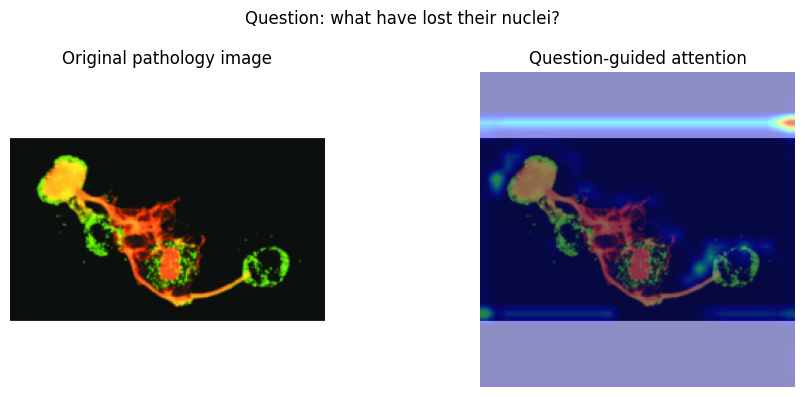

Predicted question type: Open


In [14]:
# Display the question-conditioned attention heatmap as a qualitative illustration.
model.eval()
example=clean_val[0]
image=preprocess_image(example['image'])
question=torch.tensor(encode_question(example['question']),dtype=torch.long)
with torch.no_grad():
    yn,op,ty,att=model(image.unsqueeze(0).to(device),question.unsqueeze(0).to(device),return_attention=True)
heat=F.interpolate(att[0].reshape(1,1,28,28),size=(224,224),mode='bilinear',align_corners=False)[0,0].cpu()
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].imshow(image.permute(1,2,0).numpy());axes[0].set_title('Original pathology image')
axes[1].imshow(image.permute(1,2,0).numpy());axes[1].imshow(heat,cmap='jet',alpha=0.45)
axes[1].set_title('Question-guided attention')
for ax in axes:ax.axis('off')
plt.suptitle('Question: '+str(example['question'])[:100]);plt.tight_layout();plt.show()
print('Predicted question type:', ['Yes/No','Open'][ty.argmax(1).item()])

## 15. Plot training curves and compare with all baselines

Earlier baseline results are from prior validation experiments; QTAF-Net values are calculated here. All baseline comparisons in this table use **oracle routing**.

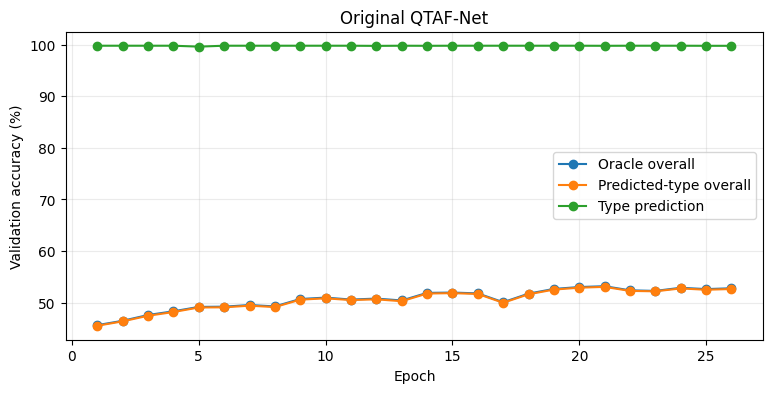

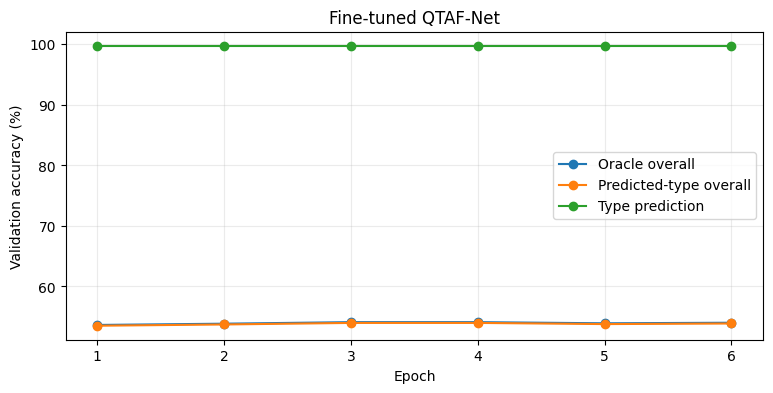

,Model,Overall (%),Yes/No (%),Open (%)
0,Image-Only CNN (fine-tuned),32.21,54.69,9.80
1,Question-Only BiLSTM (fine-tuned),48.20,85.25,11.26
2,CNN + BiLSTM (fine-tuned),54.26,86.24,22.37
3,SAN (fine-tuned),54.39,86.02,22.85
4,QTAF-Net (original),53.20,85.95,20.55
5,QTAF-Net (fine-tuned),54.10,85.98,22.30


QTAF-Net predicted-type overall (original): 53.08%
QTAF-Net predicted-type overall (fine-tuned): 53.97%


In [15]:
# Load training histories and compare validation learning curves with the baselines.
def load_history(name):
    paths=glob.glob('/kaggle/working/'+name)+glob.glob('/kaggle/input/**/'+name,recursive=True)
    return pd.read_csv(paths[0]) if paths else None
for title,filename,xcol in [
    ('Original QTAF-Net','qtaf_net_history.csv','epoch'),
    ('Fine-tuned QTAF-Net','qtaf_net_finetune_history.csv','finetune_epoch')]:
    df=load_history(filename)
    if df is None:
        print('Missing history:',filename);continue
    plt.figure(figsize=(9,4))
    for key,label in [('overall_accuracy','Oracle overall'),
                      ('predicted_overall_accuracy','Predicted-type overall'),
                      ('type_accuracy','Type prediction')]:
        plt.plot(df[xcol],100*df[key],marker='o',label=label)
    plt.xlabel('Epoch');plt.ylabel('Validation accuracy (%)');plt.title(title)
    plt.grid(alpha=0.25);plt.legend();plt.show()

comparison=pd.DataFrame([
    {'Model':'Image-Only CNN (fine-tuned)','Overall (%)':32.21,'Yes/No (%)':54.69,'Open (%)':9.80},
    {'Model':'Question-Only BiLSTM (fine-tuned)','Overall (%)':48.20,'Yes/No (%)':85.25,'Open (%)':11.26},
    {'Model':'CNN + BiLSTM (fine-tuned)','Overall (%)':54.26,'Yes/No (%)':86.24,'Open (%)':22.37},
    {'Model':'SAN (fine-tuned)','Overall (%)':54.39,'Yes/No (%)':86.02,'Open (%)':22.85},
    {'Model':'QTAF-Net (original)','Overall (%)':100*original_metrics['overall_accuracy'],
     'Yes/No (%)':100*original_metrics['closed_accuracy'],'Open (%)':100*original_metrics['open_accuracy']},
    {'Model':'QTAF-Net (fine-tuned)','Overall (%)':100*finetuned_metrics['overall_accuracy'],
     'Yes/No (%)':100*finetuned_metrics['closed_accuracy'],'Open (%)':100*finetuned_metrics['open_accuracy']},
])
display(comparison.round(2))
comparison.to_csv('/kaggle/working/qtaf_net_baseline_comparison.csv',index=False)
print('QTAF-Net predicted-type overall (original):',f"{original_metrics['predicted_overall_accuracy']:.2%}")
print('QTAF-Net predicted-type overall (fine-tuned):',f"{finetuned_metrics['predicted_overall_accuracy']:.2%}")

**Submission outputs:** Keep both original and fine-tuned best checkpoints, history CSV files and the notebook. The final test comparison is performed separately with a shared evaluation notebook.

## 16. Backup checkpoints and results

Download `qtaf_net_experiment_backup.zip` from Kaggle outputs before the session expires. **Also retain your baseline checkpoint backups** for the next ablation and final evaluation notebook.

In [16]:
# Collect checkpoint and result files into a Kaggle backup archive.
filenames=['best_qtaf_net.pth','qtaf_net_latest.pth','qtaf_net_history.csv',
           'best_qtaf_net_finetuned.pth','qtaf_net_finetune_latest.pth',
           'qtaf_net_finetune_history.csv','qtaf_net_baseline_comparison.csv']
zip_path='/kaggle/working/qtaf_net_experiment_backup.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as zf:
    for filename in filenames:
        path='/kaggle/working/'+filename
        if os.path.isfile(path):
            zf.write(path,arcname=filename);print('Added:',filename)
        else:print('Not available:',filename)
print('Backup ready:',zip_path)

Added: best_qtaf_net.pth
Added: qtaf_net_latest.pth
Added: qtaf_net_history.csv
Added: best_qtaf_net_finetuned.pth
Added: qtaf_net_finetune_latest.pth
Added: qtaf_net_finetune_history.csv
Added: qtaf_net_baseline_comparison.csv
Backup ready: /kaggle/working/qtaf_net_experiment_backup.zip


## 17. Next notebook: comparison, ablation, and final evaluation

**Ablations to train separately, from scratch:** remove question-type gating (replace soft type probabilities with a single shared fusion), remove spatial attention (global average pool visual grid), and remove auxiliary type-classification loss (still predict type, but no direct supervision). Keep the same dataset, training budget, checkpoint-selection criterion, and random seeds where possible. Compare against the full model.

**Final evaluation:** select architectures/hyperparameters using validation only; evaluate the untouched test split once the protocol is frozen. Include oracle and predicted-type metrics, yes/no/open breakdown, type prediction accuracy, answer vocabulary coverage, and error analysis. For a strict comparison, add a learned answer-type predictor to earlier baselines or evaluate all models using a common non-oracle routing procedure.

**Report:** methodology, training-from-scratch constraints, results, ablations, limitations (including oracle routing and OOV answers), visualizations, and reproducibility information.